# 09 - Evaluación y comparación

## Objetivo

Evaluar la red entrenada con el conjunto de **test**. Una vez terminado esto se la comparara con la baseline.
Se informan recall de melanoma, F1 macro, matriz de confusion e intervalos de confianza por bootstrap.

## 1. Importación y carga del modelo

In [7]:
import sys
sys.path.append("..")

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

from src.utils import fijar_semillas
from src.dataset import LesionDataset, get_transforms
from src.modelo import crear_modelo
from src.entrenamiento import probabilidades

fijar_semillas()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROCESSED = Path("../data/processed")
MODELOS = Path("../models")

modelo = crear_modelo(preentrenado=False).to(device)
modelo.load_state_dict(torch.load(MODELOS / "cnn_resnet18.pt", map_location=device, weights_only=True))
modelo.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 2. Elección del umbral con validación

El umbral por defecto es 0.5.

In [8]:
val_df = pd.read_csv(PROCESSED / "val_cnn.csv")
dl_val = DataLoader(LesionDataset(val_df, get_transforms(False)),
                    batch_size=32, shuffle=False, num_workers=0)
probs_val, y_val = probabilidades(modelo, dl_val, device)

filas = []
for u in [0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (probs_val >= u).astype(int)
    filas.append({
        "umbral": u,
        "recall": recall_score(y_val, p),
        "f1_macro": f1_score(y_val, p, average="macro"),
        "falsos_positivos": int(((p == 1) & (y_val == 0)).sum()),
        "falsos_negativos": int(((p == 0) & (y_val == 1)).sum()),
    })
pd.DataFrame(filas).round(3)

,umbral,recall,f1_macro,falsos_positivos,falsos_negativos
0,0.4,0.959,0.814,32,4
1,0.5,0.908,0.811,28,9
2,0.6,0.888,0.827,23,11
3,0.7,0.857,0.848,16,14
4,0.8,0.776,0.832,11,22


In [9]:
UMBRAL = 0.7 # porque tiene mayor F1 con recall alto

**Elección del umbral:** se fijó antes de evaluar en test, usando solo validación.
Criterio: entre los umbrales con recall de melanoma ≥ 0,85, el de mayor F1 macro.
Resultado: 0,7 (recall 0,857, F1 macro 0,848).

## 3. Evaluación con prueba

Umbral: 0.7
Recall melanoma: 0.902
F1 macro: 0.886
              precision    recall  f1-score   support

        nevo       0.90      0.87      0.88       123
    melanoma       0.87      0.90      0.89       123

    accuracy                           0.89       246
   macro avg       0.89      0.89      0.89       246
weighted avg       0.89      0.89      0.89       246



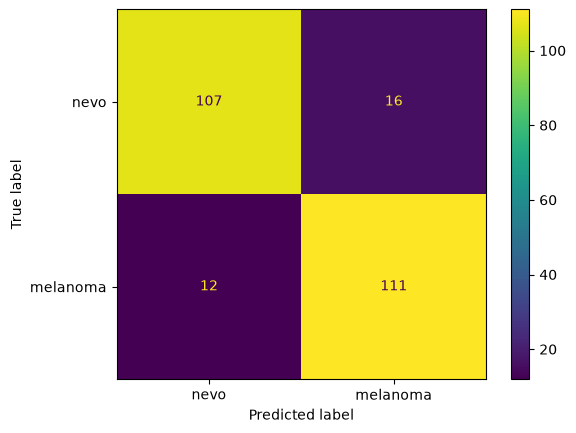

In [10]:
test_df = pd.read_csv(PROCESSED / "test.csv")
dl_test = DataLoader(LesionDataset(test_df, get_transforms(False)),
                     batch_size=32, shuffle=False, num_workers=0)
probs_test, y_test = probabilidades(modelo, dl_test, device)
pred_cnn = (probs_test >= UMBRAL).astype(int)

print("Umbral:", UMBRAL)
print("Recall melanoma:", round(recall_score(y_test, pred_cnn), 3))
print("F1 macro:", round(f1_score(y_test, pred_cnn, average="macro"), 3))
print(classification_report(y_test, pred_cnn, target_names=["nevo", "melanoma"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_cnn),
                       display_labels=["nevo", "melanoma"]).plot()
plt.show()

## 4. Intervalos de confianza

In [ ]:
def bootstrap_ic(y, pred, metrica, n=2000, seed=42):
    rng = np.random.default_rng(seed)
    idx = np.arange(len(y))
    valores = []
    for _ in range(n):
        s = rng.choice(idx, size=len(idx))
        valores.append(metrica(y[s], pred[s]))
    return np.percentile(valores, [2.5, 97.5])

m_recall = lambda y, p: recall_score(y, p)
m_f1 = lambda y, p: f1_score(y, p, average="macro")

ic_r = bootstrap_ic(y_test, pred_cnn, m_recall)
ic_f = bootstrap_ic(y_test, pred_cnn, m_f1)
print(f"Recall: {recall_score(y_test, pred_cnn):.3f}  IC95% [{ic_r[0]:.3f}, {ic_r[1]:.3f}]")
print(f"F1 macro: {f1_score(y_test, pred_cnn, average='macro'):.3f}  IC95% [{ic_f[0]:.3f}, {ic_f[1]:.3f}]")

Recall: 0.902  IC95% [0.847, 0.951]
F1 macro: 0.886  IC95% [0.844, 0.927]


## 5. Comparación con el baseline

In [ ]:
feat_train = pd.read_csv(PROCESSED / "features_train.csv")
feat_test = pd.read_csv(PROCESSED / "features_test.csv")
cols = [c for c in feat_train.columns if c not in ("image_id", "etiqueta")]

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(feat_train[cols], feat_train["etiqueta"])
feat_test["pred_rf"] = rf.predict(feat_test[cols])

res = test_df[["image_id", "etiqueta"]].copy()
res["pred_cnn"] = pred_cnn
res = res.merge(feat_test[["image_id", "pred_rf"]], on="image_id", how="inner")
print("Imágenes comparadas:", len(res), "de", len(test_df))

y = res["etiqueta"].values
filas = []
for nombre, col in [("Baseline (RF + OpenCV)", "pred_rf"), ("CNN (ResNet18)", "pred_cnn")]:
    p = res[col].values
    ic_r = bootstrap_ic(y, p, m_recall)
    ic_f = bootstrap_ic(y, p, m_f1)
    filas.append({
        "modelo": nombre,
        "recall_mel": round(recall_score(y, p), 3),
        "IC95_recall": f"[{ic_r[0]:.2f}, {ic_r[1]:.2f}]",
        "f1_macro": round(f1_score(y, p, average="macro"), 3),
        "IC95_f1": f"[{ic_f[0]:.2f}, {ic_f[1]:.2f}]",
        "falsos_negativos": int(((p == 0) & (y == 1)).sum()),
        "falsos_positivos": int(((p == 1) & (y == 0)).sum()),
    })
pd.DataFrame(filas).set_index("modelo")

Imágenes comparadas: 246 de 246


,recall_mel,IC95_recall,f1_macro,IC95_f1,falsos_negativos,falsos_positivos
modelo,,,,,,
Baseline (RF + OpenCV),0.886,"[0.83, 0.94]",0.841,"[0.79, 0.89]",14,25
CNN (ResNet18),0.902,"[0.85, 0.95]",0.886,"[0.84, 0.93]",12,16


## Conclusión

En el conjunto de prueba, la CNN ResNet18 obtuvo un recall de melanoma de 0,902 y un F1 macro de 0,886, frente a 0,886 y 0,841, respectivamente, para el baseline de Random Forest con características extraídas mediante OpenCV. En esta evaluación, la CNN también registró menos falsos negativos (12 frente a 14) y falsos positivos (16 frente a 25). Estos resultados muestran un mejor desempeño observado de la CNN en las métricas consideradas.